# Experiment 5: Reinforcement Learning (Tabular Q-Learning)
**CSAI4014 AISR Laboratory** | Name: `<Suhani Baderia>` | SAP ID: `<500119327>` | Batch: `<4>`

An agent learns to cross a grid world from **S** to **G** while avoiding walls and a pit, using
tabular Q-learning with ε-greedy exploration:

$Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$

We compare three exploration rates ε, plot learning curves, extract the greedy policy and check
it against the optimal policy computed by value iteration.

In [1]:
import os
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

os.makedirs("figs", exist_ok=True)
os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| Matplotlib:", matplotlib.__version__)
print("OS    :", platform.platform())

Python: 3.13.9 | NumPy: 2.3.5 | Matplotlib: 3.10.6
OS    : Windows-11-10.0.26300-SP0


## Environment
`.` free, `#` wall, `P` pit (terminal, −10), `G` goal (terminal, +10), `S` start.
Every move costs −1. Bumping a wall or the edge leaves the agent where it is (still −1).
Episodes end at a terminal cell or after `MAX_STEPS`.

In [2]:
GRID = [
    "S...#...",
    ".##.#.#.",
    "....#.#.",
    ".#....#.",
    ".#.##.P.",
    ".#......",
    "...#.##G",
]
ROWS, COLS = len(GRID), len(GRID[0])
ACTIONS = [(-1, 0), (0, 1), (1, 0), (0, -1)]       # N, E, S, W
ARROWS = ["↑", "→", "↓", "←"]
R_STEP, R_GOAL, R_PIT = -1.0, 10.0, -10.0
MAX_STEPS = 200
start = next((r, c) for r in range(ROWS) for c in range(COLS) if GRID[r][c] == "S")

def step(state, a):
    r, c = state
    nr, nc = r + ACTIONS[a][0], c + ACTIONS[a][1]
    if not (0 <= nr < ROWS and 0 <= nc < COLS) or GRID[nr][nc] == "#":
        nr, nc = r, c
    cell = GRID[nr][nc]
    if cell == "G":
        return (nr, nc), R_STEP + R_GOAL, True
    if cell == "P":
        return (nr, nc), R_STEP + R_PIT, True
    return (nr, nc), R_STEP, False

## Parameters

In [3]:
ALPHA, GAMMA = 0.1, 0.95
EPISODES = 1000
EPSILONS = [0.01, 0.1, 0.3]
N_SEEDS = 10           
BASE_SEED = 9327        

params = [
    ["Grid size", f"{ROWS} x {COLS}"], ["Start / goal", f"{start} / (6, 7)"],
    ["Rewards", f"step {R_STEP}, goal +{R_GOAL}, pit {R_PIT}"],
    ["Actions", "N, E, S, W (deterministic)"], ["Learning rate alpha", ALPHA],
    ["Discount gamma", GAMMA], ["Episodes per run", EPISODES], ["Max steps per episode", MAX_STEPS],
    ["Exploration epsilon", EPSILONS], ["Runs (seeds) per epsilon", N_SEEDS], ["Q initialisation", "zeros"],
]
for k, v in params:
    print(f"{k:<28}{v}")
np.savetxt("tables/T5_1_environment_and_parameters.csv", np.array(params, dtype=object), fmt="%s",
           delimiter=";", header="Parameter;Value", comments="")

Grid size                   7 x 8
Start / goal                (0, 0) / (6, 7)
Rewards                     step -1.0, goal +10.0, pit -10.0
Actions                     N, E, S, W (deterministic)
Learning rate alpha         0.1
Discount gamma              0.95
Episodes per run            1000
Max steps per episode       200
Exploration epsilon         [0.01, 0.1, 0.3]
Runs (seeds) per epsilon    10
Q initialisation            zeros


## Q-learning

In [4]:
def q_learning(eps, seed):
    rng = np.random.default_rng(seed)
    Q = np.zeros((ROWS, COLS, len(ACTIONS)))
    returns, lengths = np.zeros(EPISODES), np.zeros(EPISODES, dtype=int)
    for ep in range(EPISODES):
        s, G, done, t = start, 0.0, False, 0
        while not done and t < MAX_STEPS:
            if rng.random() < eps:
                a = int(rng.integers(len(ACTIONS)))
            else:                                    # greedy, random tie-break
                q = Q[s]
                a = int(rng.choice(np.flatnonzero(q == q.max())))
            s2, r, done = step(s, a)
            target = r if done else r + GAMMA * Q[s2].max()
            Q[s][a] += ALPHA * (target - Q[s][a])
            s, G, t = s2, G + r, t + 1
        returns[ep], lengths[ep] = G, t
    return Q, returns, lengths

runs = {eps: [q_learning(eps, BASE_SEED + i) for i in range(N_SEEDS)] for eps in EPSILONS}

## Optimal reference: value iteration

In [5]:
V = np.zeros((ROWS, COLS))
for _ in range(1000):
    V_new = np.zeros_like(V)
    for r in range(ROWS):
        for c in range(COLS):
            if GRID[r][c] in "#GP":
                continue
            V_new[r, c] = max(rew + (0 if d else GAMMA * V[s2]) for s2, rew, d in
                              (step((r, c), a) for a in range(4)))
    if np.abs(V_new - V).max() < 1e-10:
        break
    V = V_new

def greedy_rollout(Q):
    s, G, path = start, 0.0, [start]
    for _ in range(MAX_STEPS):
        s, r, done = step(s, int(np.argmax(Q[s])))
        G += r; path.append(s)
        if done:
            return G, path, GRID[s[0]][s[1]] == "G"
    return G, path, False

opt_return = None
Q_opt = np.zeros((ROWS, COLS, 4))
for r in range(ROWS):
    for c in range(COLS):
        for a in range(4):
            s2, rew, d = step((r, c), a)
            Q_opt[r, c, a] = rew + (0 if d else GAMMA * V[s2])
opt_return, opt_path, _ = greedy_rollout(Q_opt)
print(f"Optimal (value iteration): {len(opt_path)-1} moves, undiscounted return {opt_return:.0f}")

Optimal (value iteration): 13 moves, undiscounted return -3


## Mean return over the last 100 episodes

In [6]:
rows = []
print(f"{'eps':>6}{'Mean return (last 100)':>24}{'Std over seeds':>16}{'Greedy return':>15}{'Optimal runs':>14}")
for eps in EPSILONS:
    last = np.array([ret[-100:].mean() for _, ret, _ in runs[eps]])
    greedy = [greedy_rollout(Q) for Q, _, _ in runs[eps]]
    n_opt = sum(g[2] and abs(g[0] - opt_return) < 1e-9 for g in greedy)
    rows.append([eps, last.mean(), last.std(), np.mean([g[0] for g in greedy]), f"{n_opt}/{N_SEEDS}"])
    print(f"{eps:6.2f}{last.mean():24.2f}{last.std():16.2f}{rows[-1][3]:15.2f}{rows[-1][4]:>14}")
np.savetxt("tables/T5_2_mean_return_last100.csv", np.array(rows, dtype=object), fmt="%s", delimiter=",",
           header="epsilon,Mean return last 100 episodes,Std over seeds,Greedy-policy return,Runs with optimal greedy policy",
           comments="")
print(f"(Optimal return = {opt_return:.0f}; a return below it while training is the cost of exploring.)")

   eps  Mean return (last 100)  Std over seeds  Greedy return  Optimal runs
  0.01                   -3.29            0.12          -3.00         10/10
  0.10                   -5.43            0.53          -3.00         10/10
  0.30                  -11.89            0.69          -3.00         10/10
(Optimal return = -3; a return below it while training is the cost of exploring.)


## Figure 5.1 – learning curves

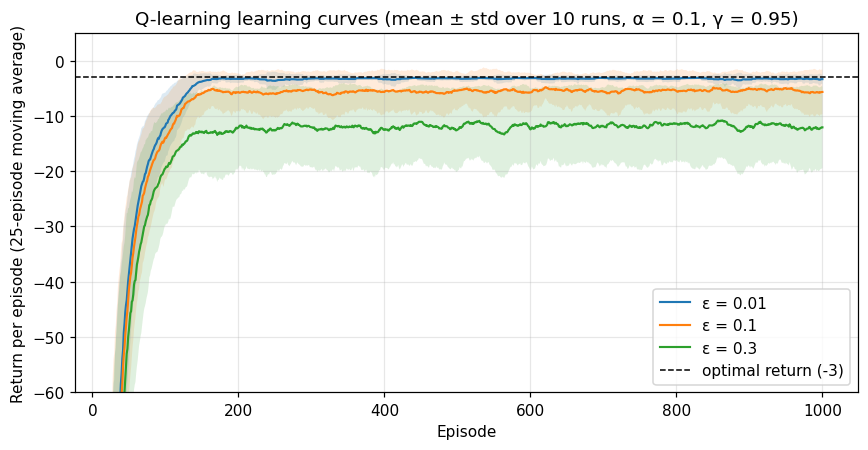

In [7]:
def smooth(y, w=25):
    return np.convolve(y, np.ones(w) / w, mode="valid")

fig, ax = plt.subplots(figsize=(8, 4.2))
for eps in EPSILONS:
    R = np.array([ret for _, ret, _ in runs[eps]])
    m = smooth(R.mean(0)); sd = smooth(R.std(0))
    x = np.arange(len(m)) + 25
    ax.plot(x, m, lw=1.4, label=f"ε = {eps}")
    ax.fill_between(x, m - sd, m + sd, alpha=0.15)
ax.axhline(opt_return, color="k", ls="--", lw=1, label=f"optimal return ({opt_return:.0f})")
ax.set_ylim(-60, 5)
ax.set_xlabel("Episode")
ax.set_ylabel("Return per episode (25-episode moving average)")
ax.set_title(f"Q-learning learning curves (mean ± std over {N_SEEDS} runs, α = {ALPHA}, γ = {GAMMA})")
ax.grid(alpha=0.3); ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("figs/fig5_1_learning_curves.png")
plt.show()

## Figure 5.2 – extracted greedy policy (ε = 0.1, first seed)

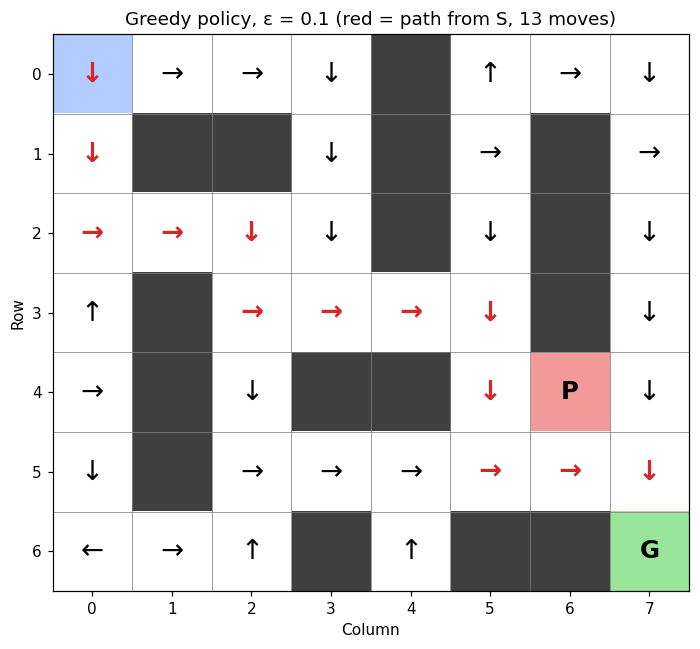

Policy grid (text):
↓ → → ↓ # ↑ → ↓
↓ # # ↓ # → # →
→ → ↓ ↓ # ↓ # ↓
↑ # → → → ↓ # ↓
→ # ↓ # # ↓ P ↓
↓ # → → → → → ↓
← → ↑ # ↑ # # G

Greedy path: 13 moves, return -3; optimal: 13 moves, return -3  ->  policy from S is OPTIMAL
Cells whose greedy action is sub-optimal: 5 of 38: [(0, 5), (1, 5), (1, 7), (4, 0), (6, 0)]


In [8]:
EPS_SHOW = 0.1
Q_show = runs[EPS_SHOW][0][0]
G_show, path_show, reached = greedy_rollout(Q_show)

fig, ax = plt.subplots(figsize=(7, 6))
colour = np.zeros((ROWS, COLS, 3)) + 1
for r in range(ROWS):
    for c in range(COLS):
        colour[r, c] = {"#": (0.25, 0.25, 0.25), "P": (0.95, 0.6, 0.6), "G": (0.6, 0.9, 0.6),
                        "S": (0.7, 0.8, 1.0)}.get(GRID[r][c], (1, 1, 1))
ax.imshow(colour)
for r in range(ROWS):
    for c in range(COLS):
        ch = GRID[r][c]
        if ch in "#":
            continue
        if ch in "GP":
            ax.text(c, r, ch, ha="center", va="center", fontsize=16, weight="bold"); continue
        a = int(np.argmax(Q_show[r, c]))
        on_path = (r, c) in path_show
        ax.text(c, r, ARROWS[a], ha="center", va="center", fontsize=18,
                color="tab:red" if on_path else "k", weight="bold" if on_path else "normal")
ax.set_xticks(range(COLS)); ax.set_yticks(range(ROWS))
ax.set_xticks(np.arange(-.5, COLS), minor=True); ax.set_yticks(np.arange(-.5, ROWS), minor=True)
ax.grid(which="minor", color="gray", lw=0.5); ax.tick_params(which="minor", length=0)
ax.set_xlabel("Column"); ax.set_ylabel("Row")
ax.set_title(f"Greedy policy, ε = {EPS_SHOW} (red = path from S, {len(path_show)-1} moves)")
fig.tight_layout()
fig.savefig("figs/fig5_2_greedy_policy.png")
plt.show()

print("Policy grid (text):")
for r in range(ROWS):
    print(" ".join(GRID[r][c] if GRID[r][c] in "#GP" else ARROWS[int(np.argmax(Q_show[r, c]))] for c in range(COLS)))
is_opt = reached and abs(G_show - opt_return) < 1e-9
print(f"\nGreedy path: {len(path_show)-1} moves, return {G_show:.0f}; optimal: {len(opt_path)-1} moves,"
      f" return {opt_return:.0f}  ->  policy from S is {'OPTIMAL' if is_opt else 'NOT optimal'}")
# Cells where the greedy action differs from every optimal action (rarely-visited cells):
diff = [(r, c) for r in range(ROWS) for c in range(COLS) if GRID[r][c] not in "#GP"
        and Q_opt[r, c, int(np.argmax(Q_show[r, c]))] < Q_opt[r, c].max() - 1e-9]
print(f"Cells whose greedy action is sub-optimal: {len(diff)} of {sum(ch not in '#GP' for row in GRID for ch in row)}: {diff}")